<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone%204/Active_learning_and_human_in_the_loop_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Active learning and human-in-the-loop simulation

ACTIVE LEARNING with continual updates (full retrain on new data + replay buffer, bootstrap gate)


,strategy,cycle,labeled_users,candidate_qini,candidate_uplift@10%,promoted,gate_CI,deployed_qini,scoring_trees,scoring_us_per_user,update_s
0,random,0,489285,0.000290,0.007154,None,,0.000290,38,0.782000,0.000000
1,random,1,978570,0.000339,0.007466,False,"[-0.000296, 0.000175]",0.000290,38,0.790000,53.100000
2,random,2,1467855,0.000310,0.007274,False,"[-0.000067, 0.000391]",0.000290,38,0.785000,48.000000
3,random,3,1957140,0.000372,0.007698,False,"[-0.000284, 0.000138]",0.000290,38,0.782000,47.900000
4,random,4,2446425,0.000336,0.007618,False,"[-0.000232, 0.000149]",0.000290,38,0.802000,49.200000
5,random,5,2935710,0.000319,0.007326,False,"[-0.000144, 0.000290]",0.000290,38,0.783000,46.900000
6,active (hybrid),0,489285,0.000290,0.007154,None,,0.000290,38,0.785000,0.000000
7,active (hybrid),1,978570,0.000381,0.008053,False,"[-0.000239, 0.000134]",0.000290,38,0.783000,51.900000
8,active (hybrid),2,1467855,0.000386,0.007981,False,"[-0.000157, 0.000258]",0.000290,38,0.792000,92.300000
9,active (hybrid),3,1957140,0.000355,0.008046,False,"[-0.000187, 0.000285]",0.000290,38,0.795000,75.800000


strategy,random,active (hybrid)
final_candidate_qini,0.000319,0.000349
final_deployed_qini,0.000290,0.000290
users_to_reach_random_final_qini,2935710,978570
promotions,0/5,0/5
deployed_top10%_overlap,1.000000,1.000000
candidate_top10%_overlap,0.717220,0.743340
final_scoring_trees,38,38
final_scoring_us_per_user,0.783000,0.781000
mean_update_s,49.020000,67.220000


Labeling burden: active learning needs 67% fewer experiment users


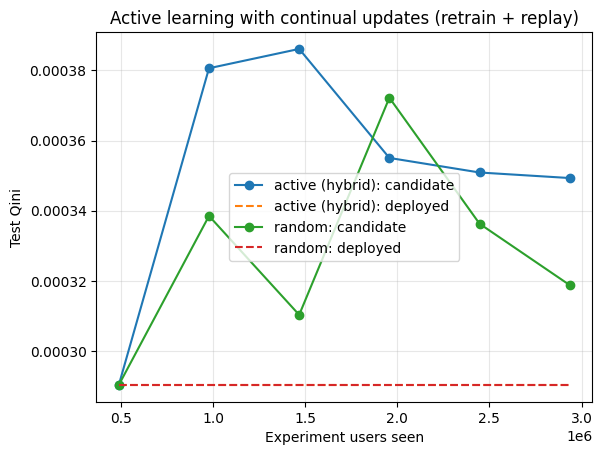


HUMAN LABEL CURATION: 3,397 fake conversions injected into 8,493 real ones


,strategy,cycle,reviewed_conversions,fakes_left,candidate_qini,candidate_%_of_clean,promoted,gate_CI,deployed_qini,deployed_%_of_clean,uplift@10%,update_s
0,random review,0,0,3397,0.000361,95.102306,None,,0.000361,95.102306,0.007169,0.000000
1,random review,1,1783,2903,0.000381,100.518591,False,"[-0.000180, 0.000023]",0.000361,95.102306,0.007169,110.300000
2,random review,2,3566,2371,0.000376,99.048272,False,"[-0.000030, 0.000080]",0.000361,95.102306,0.007169,119.100000
3,random review,3,5349,1838,0.000383,100.884658,False,"[-0.000132, 0.000084]",0.000361,95.102306,0.007169,125.700000
4,targeted review,0,0,3397,0.000361,95.102306,None,,0.000361,95.102306,0.007169,0.000000
5,targeted review,1,1783,1727,0.000371,97.694752,False,"[-0.000112, 0.000119]",0.000361,95.102306,0.007169,129.200000
6,targeted review,2,3566,183,0.000354,93.177556,False,"[-0.000197, 0.000114]",0.000361,95.102306,0.007169,122.600000
7,targeted review,3,5349,183,0.000380,100.126700,False,"[-0.000225, 0.000076]",0.000361,95.102306,0.007169,118.900000


strategy,random review,targeted review
final_candidate_%_of_clean,100.884658,100.126700
final_deployed_%_of_clean,95.102306,95.102306
reviews_to_remove_90%_fakes,not reached,3566
%_of_conversions_reviewed,-,30%
promotions,0/3,0/3
score_rank_corr_between_cycles,1.000000,1.000000
top10%_overlap_between_cycles,1.000000,1.000000


Clean labels Qini 0.000379 | before curation 0.000361 (95% of clean)


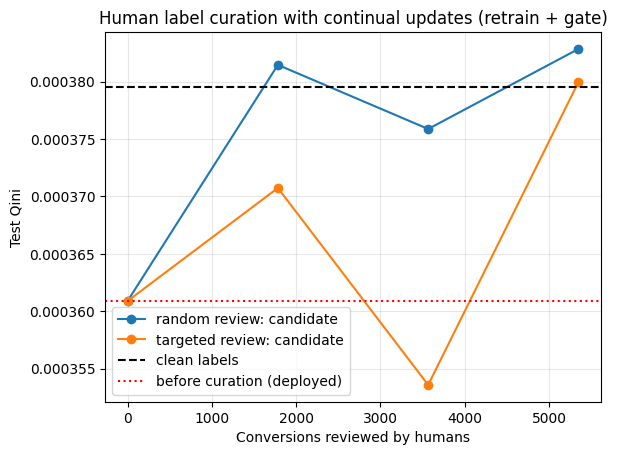

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from scipy.stats import spearmanr

BUFFER_SIZE = 200_000
GATE_ROWS, GATE_RESAMPLES = 250_000, 100
INIT_FRAC, BATCH_FRAC, ROUNDS = 0.05, 0.05, 5
THRESHOLD, W_UNC, W_MARGIN, W_DIV = 0.001, 0.5, 0.3, 0.2
HITL_FRAC, FAKE_SHARE, REVIEW_SHARE, CYCLES = 0.3, 0.4, 0.15, 3
HIT_RATE, FALSE_FLAG = 0.95, 0.02

mu, sd = Xtr[:, :12].mean(0), Xtr[:, :12].std(0)
km = MiniBatchKMeans(n_clusters=50, random_state=SEED, n_init=3).fit((Xtr[::20, :12] - mu) / sd)
cluster = km.predict((Xtr[:, :12] - mu) / sd)
eval_idx = np.random.default_rng(SEED).choice(len(yte), min(100_000, len(yte)), replace=False)

perm = np.random.default_rng(SEED).permutation(len(yva))
g_idx = perm[: min(GATE_ROWS, len(yva) // 2)]; e_idx = perm[len(g_idx):]
Xg, tg, yg = Xva[g_idx], tva[g_idx], yva[g_idx]
Xe, te_, ye = Xva[e_idx], tva[e_idx], yva[e_idx]

def fit_scratch(idx, y=None):
    global ttr, ytr, tva, yva
    old = (ttr, ytr, tva, yva)
    ttr, ytr = ttr[idx], (ytr if y is None else y)[idx]; tva, yva = te_, ye
    try: return fit_x(Xtr[idx], Xe, clf_best, reg_best)
    finally: ttr, ytr, tva, yva = old

def gate(cand, dep):
    """Paired bootstrap on gate users: promote only if the 2.5th percentile of the Qini gain is above 0."""
    (lo, hi), _ = boot(yg, tg, pred_x(cand, Xg), pred_x(dep, Xg), n=GATE_RESAMPLES)
    return lo, hi

def evaluate(m):
    s = pred_x(m, Xte)
    return s, qini(yte, tte, s), uplift_at(yte, tte, s, 0.1)

def cost(m):
    trees = sum(m[k].best_iteration + 1 for k in ["tau0", "tau1"])
    times = []
    for _ in range(3):
        t0 = time.perf_counter(); pred_x(m, Xte); times.append(time.perf_counter() - t0)
    return trees, 1e6 * min(times) / len(yte)

def stability(scores):
    k = len(eval_idx) // 10
    top = lambda s: set(np.argsort(-s[eval_idx])[:k])
    rho = [spearmanr(a[eval_idx], b[eval_idx])[0] for a, b in zip(scores, scores[1:])]
    ov = [len(top(a) & top(b)) / k for a, b in zip(scores, scores[1:])]
    return np.mean(rho), np.mean(ov)

def reservoir(seen, rng):
    return seen if len(seen) <= BUFFER_SIZE else rng.choice(seen, BUFFER_SIZE, replace=False)

# ---------------- Active learning with continual (warm-start + replay) updates ----------------
def informativeness(m, pool, labeled):
    t0, t1 = m["tau0"].predict(Xtr[pool]), m["tau1"].predict(Xtr[pool])
    u = m["g"] * t0 + (1 - m["g"]) * t1
    share = np.bincount(cluster[labeled], minlength=50) / labeled.size
    r = lambda v: pd.Series(v).rank(pct=True).values
    return W_UNC * r(np.abs(t0 - t1)) + W_MARGIN * r(-np.abs(u - THRESHOLD)) + W_DIV * r(-share[cluster[pool]])

def simulate_al(strategy):
    rng = np.random.default_rng(SEED)
    n, batch = len(ytr), int(BATCH_FRAC * len(ytr))
    seen = rng.choice(n, int(INIT_FRAC * n), replace=False)
    dep = fit_scratch(seen); buf = reservoir(seen, rng)
    rows, scores, cscores = [], [], []
    for cyc in range(ROUNDS + 1):
        upd, lo, hi, promoted, cand = 0.0, np.nan, np.nan, None, dep
        if cyc > 0:
            free = np.ones(n, bool); free[seen] = False; pool = np.flatnonzero(free)
            new = rng.choice(pool, batch, replace=False) if strategy == "random" else \
                  pool[np.argsort(-informativeness(dep, pool, seen))[:batch]]
            t0 = time.perf_counter(); cand = fit_scratch(np.concatenate([new, buf])); upd = time.perf_counter() - t0
            lo, hi = gate(cand, dep); promoted = bool(lo > 0)
            if promoted: dep = cand
            seen = np.concatenate([seen, new]); buf = reservoir(seen, rng)
        s, q, u10 = evaluate(dep); scores.append(s); trees, us = cost(dep)
        cs, cq, cu = evaluate(cand); cscores.append(cs)
        rows.append({"strategy": strategy, "cycle": cyc, "labeled_users": len(seen), "candidate_qini": cq,
                     "candidate_uplift@10%": cu, "promoted": promoted, "gate_CI": "" if cyc == 0 else f"[{lo:.6f}, {hi:.6f}]",
                     "deployed_qini": q, "scoring_trees": trees, "scoring_us_per_user": round(us, 3), "update_s": round(upd, 1)})
    return rows, scores, cscores

ra, sa, ca = simulate_al("random"); aa, sb, cb = simulate_al("active (hybrid)")
al = pd.DataFrame(ra + aa)
print("ACTIVE LEARNING with continual updates (full retrain on new data + replay buffer, bootstrap gate)"); display(al)
target = ra[-1]["candidate_qini"]
hit = next((r["labeled_users"] for r in aa[1:] if r["candidate_qini"] >= target), None)
summ = []
for name, rows, scores, cs in [("random", ra, sa, ca), ("active (hybrid)", aa, sb, cb)]:
    rho, ov = stability(scores); crho, cov = stability(cs)
    summ.append({"strategy": name, "final_candidate_qini": rows[-1]["candidate_qini"], "final_deployed_qini": rows[-1]["deployed_qini"],
                 "users_to_reach_random_final_qini": rows[-1]["labeled_users"] if name == "random" else (hit or "not reached"),
                 "promotions": f"{sum(r['promoted'] is True for r in rows)}/{ROUNDS}",
                 "deployed_top10%_overlap": ov, "candidate_top10%_overlap": cov,
                 "final_scoring_trees": rows[-1]["scoring_trees"], "final_scoring_us_per_user": rows[-1]["scoring_us_per_user"],
                 "mean_update_s": np.mean([r["update_s"] for r in rows[1:]])})
display(pd.DataFrame(summ).set_index("strategy").T)
if hit: print(f"Labeling burden: active learning needs {100 * (1 - hit / ra[-1]['labeled_users']):.0f}% fewer experiment users")

for name, g in al.groupby("strategy"):
    plt.plot(g.labeled_users, g.candidate_qini, marker="o", label=f"{name}: candidate")
    plt.plot(g.labeled_users, g.deployed_qini, ls="--", label=f"{name}: deployed")
plt.xlabel("Experiment users seen"); plt.ylabel("Test Qini"); plt.title("Active learning with continual updates (retrain + replay)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# ---------------- Human label curation with continual updates ----------------
rng = np.random.default_rng(SEED)
sub = np.zeros(len(ytr), bool); sub[rng.choice(len(ytr), int(HITL_FRAC * len(ytr)), replace=False)] = True
sub_idx = np.flatnonzero(sub)
bot_c = np.bincount(cluster[sub & (ttr == 1)], minlength=50).argmax()
cand_rows = np.flatnonzero(sub & (ttr == 1) & (ytr == 0) & (cluster == bot_c))
fake = rng.choice(cand_rows, min(len(cand_rows), int(FAKE_SHARE * ytr[sub].sum())), replace=False)
y_noisy = ytr.copy(); y_noisy[fake] = 1
is_fake = np.zeros(len(ytr), bool); is_fake[fake] = True
n_conv = int(y_noisy[sub].sum())
print(f"\nHUMAN LABEL CURATION: {len(fake):,} fake conversions injected into {int(ytr[sub].sum()):,} real ones")
q_clean = evaluate(fit_scratch(sub_idx))[1]
dep0 = fit_scratch(sub_idx, y_noisy)

def annotate(idx, cyc):
    p = np.where(is_fake[idx], HIT_RATE, FALSE_FLAG)
    return idx[np.random.default_rng(SEED + cyc).random(len(idx)) < p]

def gap_rank(y):
    gap = np.zeros(50)
    for c in range(50):
        tm, cm = sub & (cluster == c) & (ttr == 1), sub & (cluster == c) & (ttr == 0)
        nt, nc = tm.sum(), cm.sum()
        if nt and nc:
            p = y[tm | cm].mean()
            gap[c] = (y[tm].mean() - y[cm].mean()) / np.sqrt(max(p * (1 - p), 1e-12) * (1 / nt + 1 / nc))
    return gap

def simulate_hitl(strategy):
    y, reviewed, dep = y_noisy.copy(), np.zeros(len(ytr), bool), dep0
    budget, rows, scores = int(REVIEW_SHARE * n_conv), [], []
    for cyc in range(CYCLES + 1):
        upd, lo, hi, promoted, cand = 0.0, np.nan, np.nan, None, dep
        if cyc > 0:
            conv = np.flatnonzero(sub & (y == 1) & (ttr == 1) & ~reviewed)
            pick = np.random.default_rng(SEED + cyc).choice(conv, min(budget, len(conv)), replace=False) \
                   if strategy == "random review" else conv[np.argsort(-gap_rank(y)[cluster[conv]], kind="stable")[:budget]]
            reviewed[pick] = True
            y[annotate(pick, cyc)] = 0          # corrections applied to the data (and therefore the replay buffer)
            t0 = time.perf_counter(); cand = fit_scratch(sub_idx, y); upd = time.perf_counter() - t0
            lo, hi = gate(cand, dep); promoted = bool(lo > 0)
            if promoted: dep = cand
        s, q, u10 = evaluate(dep); scores.append(s); cq = evaluate(cand)[1]
        rows.append({"strategy": strategy, "cycle": cyc, "reviewed_conversions": int(reviewed.sum()),
                     "fakes_left": int((is_fake & (y == 1)).sum()), "candidate_qini": cq,
                     "candidate_%_of_clean": 100 * cq / q_clean, "promoted": promoted,
                     "gate_CI": "" if cyc == 0 else f"[{lo:.6f}, {hi:.6f}]", "deployed_qini": q,
                     "deployed_%_of_clean": 100 * q / q_clean, "uplift@10%": u10, "update_s": round(upd, 1)})
    return rows, scores

rr, s_rr = simulate_hitl("random review"); rt, s_rt = simulate_hitl("targeted review")
hitl = pd.DataFrame(rr + rt); display(hitl)
summ = []
for name, rows, scores in [("random review", rr, s_rr), ("targeted review", rt, s_rt)]:
    gone = next((r["reviewed_conversions"] for r in rows if r["fakes_left"] <= 0.1 * len(fake)), None)
    rho, ov = stability(scores)
    summ.append({"strategy": name, "final_candidate_%_of_clean": rows[-1]["candidate_%_of_clean"],
                 "final_deployed_%_of_clean": rows[-1]["deployed_%_of_clean"],
                 "reviews_to_remove_90%_fakes": gone or "not reached",
                 "%_of_conversions_reviewed": f"{100 * gone / n_conv:.0f}%" if gone else "-",
                 "promotions": f"{sum(r['promoted'] is True for r in rows)}/{CYCLES}",
                 "score_rank_corr_between_cycles": rho, "top10%_overlap_between_cycles": ov})
display(pd.DataFrame(summ).set_index("strategy").T)
print(f"Clean labels Qini {q_clean:.6f} | before curation {rr[0]['deployed_qini']:.6f} ({rr[0]['deployed_%_of_clean']:.0f}% of clean)")

for name, g in hitl.groupby("strategy"): plt.plot(g.reviewed_conversions, g.candidate_qini, marker="o", label=f"{name}: candidate")
plt.axhline(q_clean, c="k", ls="--", label="clean labels"); plt.axhline(rr[0]["deployed_qini"], c="r", ls=":", label="before curation (deployed)")
plt.xlabel("Conversions reviewed by humans"); plt.ylabel("Test Qini"); plt.title("Human label curation with continual updates (retrain + gate)")
plt.legend(); plt.grid(alpha=0.3); plt.show()